In [1]:
from google.colab import files
uploaded = files.upload()
print("file uploaded succesfully")

Saving employee_performance_500_rows.csv to employee_performance_500_rows.csv
file uploaded succesfully


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [9]:
df = pd.read_csv("employee_performance_500_rows.csv")
print(df.shape)
df.describe()


(500, 15)


,age,experience_years,attendance_percentage,tasks_assigned,tasks_completed,task_completion_rate,quality_score,average_work_hours,training_hours,workload_score,performance_score
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000,500.000000,500.000000,500.000000
mean,31.860000,6.860000,91.346000,63.834000,52.240000,81.783400,78.361800,8.2072,5.869600,66.928600,76.506800
std,5.746167,4.471267,5.624186,21.639199,18.836987,9.376038,10.253428,0.7539,3.966477,15.428107,7.546659
min,21.000000,0.400000,71.200000,25.000000,15.000000,47.800000,50.600000,5.9000,0.100000,20.000000,54.000000
25%,28.000000,3.600000,87.500000,46.000000,36.000000,75.475000,71.200000,7.7000,3.000000,56.775000,71.375000
50%,31.000000,5.800000,91.500000,64.000000,52.000000,81.550000,78.600000,8.2000,5.000000,67.650000,76.650000
75%,35.000000,9.000000,95.700000,83.000000,67.000000,88.900000,85.500000,8.7000,8.000000,77.100000,81.500000
max,50.000000,24.200000,100.000000,100.000000,98.000000,100.000000,100.000000,10.2000,28.900000,100.000000,100.000000


In [19]:
numeric_df = df.select_dtypes(include=np.number)

# Correlation matrix
corr_matrix = numeric_df.corr()

# Display correlation
print(corr_matrix["performance_score"].sort_values(
    ascending=False))

performance_score        1.000000
task_completion_rate     0.534774
quality_score            0.431130
attendance_percentage    0.216643
training_hours           0.179358
tasks_completed          0.163973
average_work_hours       0.035063
experience_years         0.012921
tasks_assigned          -0.003461
age                     -0.035262
workload_score          -0.205957
Name: performance_score, dtype: float64


In [37]:
df.isna().sum()

,0
employee_id,0
department,0
job_role,0
age,0
experience_years,0
attendance_percentage,0
tasks_assigned,0
tasks_completed,0
task_completion_rate,0
quality_score,0


In [39]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
495,False
496,False
497,False
498,False


In [17]:
df.head()

,employee_id,department,job_role,age,experience_years,attendance_percentage,tasks_assigned,tasks_completed,task_completion_rate,quality_score,average_work_hours,training_hours,workload_score,performance_score,performance_status
0,EMP0001,Sales,Sales Executive,36,7.1,96.7,49,35,71.4,87.0,6.8,8.5,55.3,75.2,On Track
1,EMP0002,Operations,Operations Executive,38,17.3,86.2,51,45,88.2,80.0,9.2,4.1,29.6,82.1,On Track
2,EMP0003,Marketing,Content Specialist,24,2.7,92.2,75,64,85.3,73.6,8.8,0.7,45.1,85.4,On Track
3,EMP0004,Finance,Financial Analyst,30,7.9,90.5,81,80,98.8,83.7,7.8,3.0,43.8,87.3,On Track
4,EMP0005,IT,Software Developer,26,1.7,77.6,71,64,90.1,78.5,7.1,4.5,85.4,80.5,On Track


In [20]:
features = [
    "attendance_percentage",
    "task_completion_rate",
    "quality_score",
    "average_work_hours",
    "training_hours",
    "workload_score",
    "tasks_completed",
    "experience_years"
]

X = df[features]
y = df["performance_score"]


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [23]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [25]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))


MAE: 4.39
RMSE: 5.55
R2 Score: 0.41


                 Feature  Importance
1   task_completion_rate    0.345805
2          quality_score    0.213036
5         workload_score    0.102587
0  attendance_percentage    0.092540
4         training_hours    0.074542
6        tasks_completed    0.061954
7       experience_years    0.057323
3     average_work_hours    0.052213


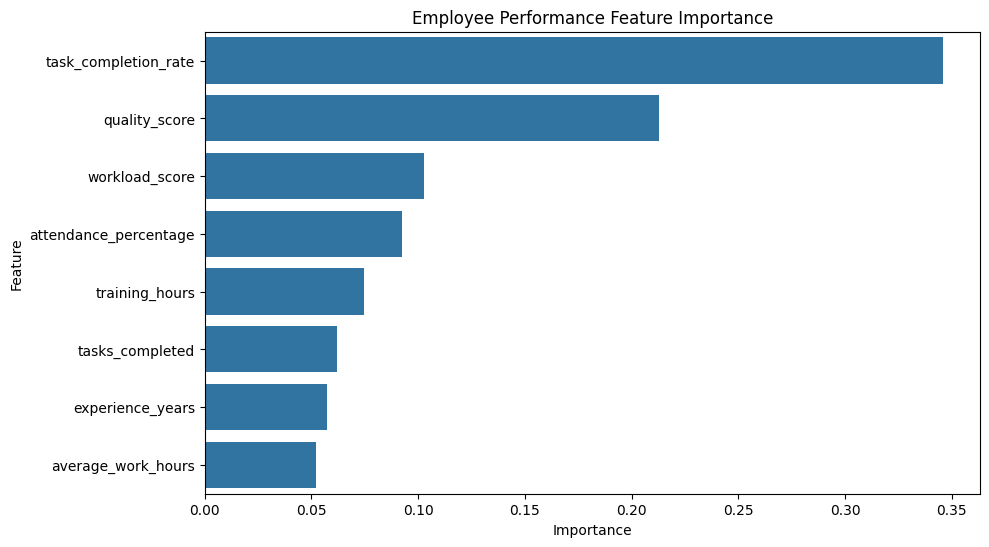

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

# Sort features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display values
print(importance_df)

# Plot graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,

    x="Importance",
    y="Feature"
)

plt.title("Employee Performance Feature Importance")
plt.show()


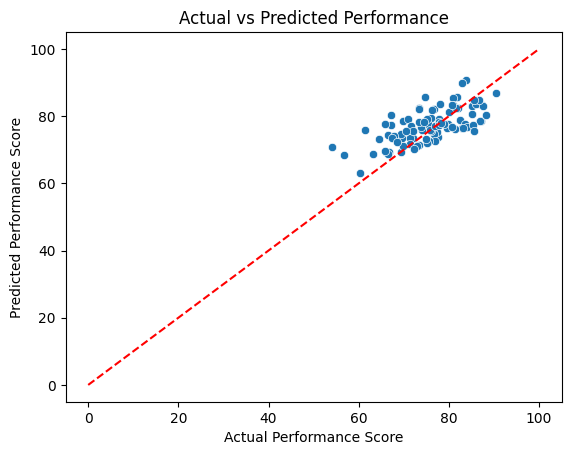

In [33]:
sns.scatterplot(
    x=y_test,
    y=y_pred
)

# Perfect prediction reference line
plt.plot(
    [0, 100],
    [0, 100],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Performance Score")
plt.ylabel("Predicted Performance Score")

plt.title("Actual vs Predicted Performance")

plt.show()



In [34]:

import joblib

joblib.dump(model, "employee_performance_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [35]:

from google.colab import files

files.download("employee_performance_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:

# New employee input

new_employee = pd.DataFrame([{
    "attendance_percentage": 19,
    "task_completion_rate": 19,
    "quality_score": 19,
    "average_work_hours": 10,
    "training_hours": 11,
    "workload_score": 24,
    "tasks_completed": 10,
    "experience_years": 17
}])

# Ensure feature order matches training
new_employee = new_employee[X.columns]

# Predict
predicted_score = model.predict(new_employee)

print("Predicted Performance Score:",
      round(predicted_score[0], 2))


Predicted Performance Score: 70.9


In [57]:

score = predicted_score[0]

if score >= 80:
    print("High Predicted Performance")
elif score >= 60:
    print("Moderate Predicted Performance")
else:
    print("Potential Support Needed")


High Predicted Performance


In [64]:

def recommend_training(employee):

    recommendations = []

    if employee["task_completion_rate"] < 70:
        recommendations.append(
            "Task Planning and Time Management Training"
        )

    if employee["quality_score"] < 70:
        recommendations.append(
            "Work Quality Improvement Training"
        )

    if employee["training_hours"] < 5:
        recommendations.append(
            "Skill Development Program"
        )

    if employee["workload_score"] > 80:
        recommendations.append(
            "Workload Management and Stress Management Support"
        )

    if not recommendations:
        recommendations.append(
            "Advanced Skill Development and Career Growth"
        )

    return recommendations


# Generate recommendations
result = recommend_training(employee)

print("Recommended Training Programs:")

for training in result:
    print("-", training)


Recommended Training Programs:
- Work Quality Improvement Training
- Workload Management and Stress Management Support


In [65]:

# Predict employee performance
score = model.predict(new_employee)[0]

# Generate recommendations using employee details
employee_details = new_employee.iloc[0].to_dict()

recommendations = recommend_training(employee_details)

print("Predicted Performance Score:", round(score, 2))

print("\nTraining Recommendations:")

for item in recommendations:
    print("-", item)


Predicted Performance Score: 70.9

Training Recommendations:
- Task Planning and Time Management Training
- Work Quality Improvement Training


In [66]:
import joblib

joblib.dump(model, "employee_performance_model.pkl")

df.to_csv("employee_performance_500_rows.csv", index=False)

print("Project files ready!")

Project files ready!


In [67]:
from google.colab import files

files.download("employee_performance_model.pkl")
files.download("employee_performance_500_rows.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>